# Copyright © 2025 Hephzibah Behulah
This notebook is a private properties with the following amandments:
- Individuals may use, share, and adapt this material for non-commercial purposes with attribution.
- Institutions/Companies must obtain written consent to use this material, except for nonprofits.
- Commercial use is prohibited without permission.  
Contact: isaacadigunoluwole@gmail.com.

❗❗❗ IMPORTANT❗❗❗ Create a copy of this notebook

In order to work with this Google Colab you need to create a copy of it. Please DO NOT provide your answers here. Instead, work on the copy version. To make a copy:

Click on: File -> save a copy in drive

Have you successfully created the copy? if yes, there must be a new tab opened in your browser. Now move to the copy and start from there

Introduction to the Datasets
The Global Superstore Sales Analysis repository showcases a comprehensive Power BI dashboard that provides valuable insights into sales performance. This project is designed to present key information and trends to stakeholders, enabling informed decision-making.

Let us first import the dataset.

In [1]:
%pip install openpyxl


Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import openpyxl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import os
import sys
import re
import json

In [3]:
import os
print("I’m working in this folder:", os.getcwd())
print("I can see these files:", os.listdir())


I’m working in this folder: /workspaces/First-Project-Global-Super-Store-Analysis
I can see these files: ['Maincode.py', 'SECURITY.md', 'GlobalSuperstore.xlsx', '.git', 'Maincodes.ipynb', 'What to do.png', '🎯 Tasks:', 'README.md']


In [4]:
# import pandas as pd

# If the file is in the main folder:
file_path = "GlobalSuperstore.xlsx"

# If you saw it inside data/, use:
# file_path = "data/GlobalSuperstore.xlsx"

df = pd.read_excel(file_path, engine="openpyxl")
df.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,32298,CA-2012-124891,2012-07-31,2012-07-31,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,...,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,2309.650,7,0.0,762.1845,933.57,Critical
1,26341,IN-2013-77878,2013-02-05,2013-02-07,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,...,FUR-CH-10003950,Furniture,Chairs,"Novimex Executive Leather Armchair, Black",3709.395,9,0.1,-288.7650,923.63,Critical
2,25330,IN-2013-71249,2013-10-17,2013-10-18,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,...,TEC-PH-10004664,Technology,Phones,"Nokia Smart Phone, with Caller ID",5175.171,9,0.1,919.9710,915.49,Medium
3,13524,ES-2013-1579342,2013-01-28,2013-01-30,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,...,TEC-PH-10004583,Technology,Phones,"Motorola Smart Phone, Cordless",2892.510,5,0.1,-96.5400,910.16,Medium
4,47221,SG-2013-4320,2013-11-05,2013-11-06,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,...,TEC-SHA-10000501,Technology,Copiers,"Sharp Wireless Fax, High-Speed",2832.960,8,0.0,311.5200,903.04,Critical


In [5]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          51290 non-null  int64         
 1   Order ID        51290 non-null  object        
 2   Order Date      51290 non-null  datetime64[ns]
 3   Ship Date       51290 non-null  datetime64[ns]
 4   Ship Mode       51290 non-null  object        
 5   Customer ID     51290 non-null  object        
 6   Customer Name   51290 non-null  object        
 7   Segment         51290 non-null  object        
 8   City            51290 non-null  object        
 9   State           51290 non-null  object        
 10  Country         51290 non-null  object        
 11  Postal Code     9994 non-null   float64       
 12  Market          51290 non-null  object        
 13  Region          51290 non-null  object        
 14  Product ID      51290 non-null  object        
 15  Ca

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit,Shipping Cost
count,51290.00000,51290,51290,9994.000000,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000
mean,25645.50000,2013-05-11 21:26:49.155781120,2013-05-15 20:42:42.745174528,55190.379428,246.490581,3.476545,0.142908,28.610982,26.375818
min,1.00000,2011-01-01 00:00:00,2011-01-03 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000,0.002000
25%,12823.25000,2012-06-19 00:00:00,2012-06-23 00:00:00,23223.000000,30.758625,2.000000,0.000000,0.000000,2.610000
50%,25645.50000,2013-07-08 00:00:00,2013-07-12 00:00:00,56430.500000,85.053000,3.000000,0.000000,9.240000,7.790000
75%,38467.75000,2014-05-22 00:00:00,2014-05-26 00:00:00,90008.000000,251.053200,5.000000,0.200000,36.810000,24.450000
max,51290.00000,2014-12-31 00:00:00,2015-01-07 00:00:00,99301.000000,22638.480000,14.000000,0.850000,8399.976000,933.570000
std,14806.29199,NaN,NaN,32063.693350,487.565361,2.278766,0.212280,174.340972,57.296810


In [6]:
# Task 1. Clean column names and remove whitespace
# Load the Excel file
file_path = "GlobalSuperstore.xlsx"
df = pd.read_excel(file_path, engine="openpyxl")

# Clean column names: strip whitespace, lowercase, replace spaces with underscores
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')
df.head()



,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,city,state,...,product_id,category,sub-category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority
0,32298,CA-2012-124891,2012-07-31,2012-07-31,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,...,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,2309.650,7,0.0,762.1845,933.57,Critical
1,26341,IN-2013-77878,2013-02-05,2013-02-07,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,...,FUR-CH-10003950,Furniture,Chairs,"Novimex Executive Leather Armchair, Black",3709.395,9,0.1,-288.7650,923.63,Critical
2,25330,IN-2013-71249,2013-10-17,2013-10-18,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,...,TEC-PH-10004664,Technology,Phones,"Nokia Smart Phone, with Caller ID",5175.171,9,0.1,919.9710,915.49,Medium
3,13524,ES-2013-1579342,2013-01-28,2013-01-30,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,...,TEC-PH-10004583,Technology,Phones,"Motorola Smart Phone, Cordless",2892.510,5,0.1,-96.5400,910.16,Medium
4,47221,SG-2013-4320,2013-11-05,2013-11-06,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,...,TEC-SHA-10000501,Technology,Copiers,"Sharp Wireless Fax, High-Speed",2832.960,8,0.0,311.5200,903.04,Critical


In [7]:
#Task 2. Aggregate sales by Region, Category, and Year
# Convert Order Date to datetime
df['order_date'] = pd.to_datetime(df['order_date'])

# Extract year from order date
df['year'] = df['order_date'].dt.year

# Group by Region, Category, and Year
agg_sales = df.groupby(['region', 'category', 'year'])['sales'].sum().reset_index()
agg_sales.head()


,region,category,year,sales
0,Africa,Furniture,2011,32944.296
1,Africa,Furniture,2012,28894.527
2,Africa,Furniture,2013,61973.100
3,Africa,Furniture,2014,70838.712
4,Africa,Office Supplies,2011,44482.254


In [8]:
#Task 3. Identify most profitable categories
# Group by category and sum profits
profitable_categories = df.groupby('category')['profit'].sum().sort_values(ascending=False).reset_index()
profitable_categories


,category,profit
0,Technology,663778.73318
1,Office Supplies,518473.83430
2,Furniture,285204.72380


In [ ]:
#Task 4. Merge customer and order tables
# Load separate sheets
orders_df = pd.read_excel(file_path, sheet_name="Orders", engine="openpyxl")
customers_df = pd.read_excel(file_path, sheet_name="Customers", engine="openpyxl")

# Merge on customer_id
merged_df = pd.merge(orders_df, customers_df, on='customer_id', how='left')
merged_df.head()
# W E HAVE NO IDEA OF THIS TASK 

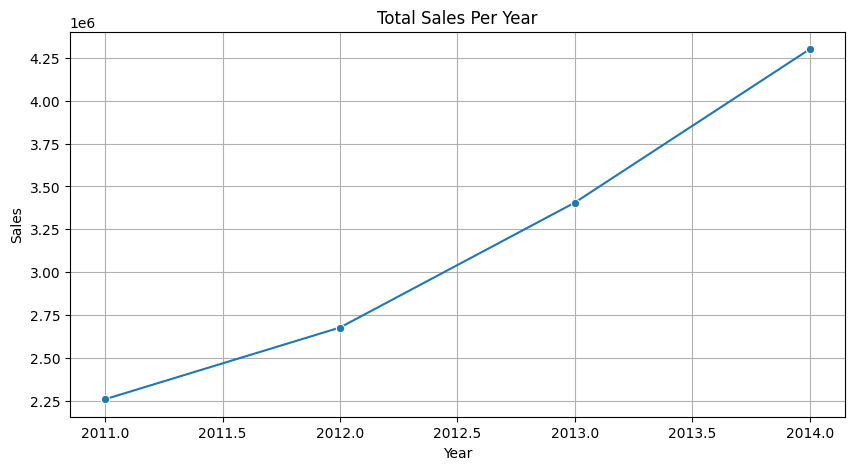

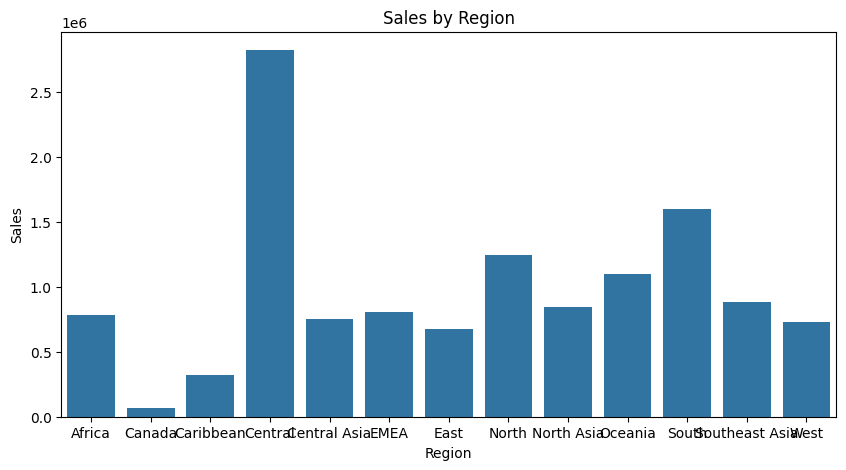

In [ ]:
#Task 5. Create bar and line plots to show revenue growth
import matplotlib.pyplot as plt
import seaborn as sns

# Plot total sales per year
sales_per_year = df.groupby('year')['sales'].sum().reset_index()

# Line Plot
plt.figure(figsize=(10,5))
sns.lineplot(x='year', y='sales', data=sales_per_year, marker='o')
plt.title('Total Sales Per Year')
plt.xlabel('Year')
plt.ylabel('Sales')
plt.grid(True)
plt.show()

# Bar Plot for Sales by Region
plt.figure(figsize=(10,5))
sns.barplot(x='region', y='sales', data=df.groupby('region')['sales'].sum().reset_index())
plt.title('Sales by Region')
plt.xlabel('Region')
plt.ylabel('Sales')
plt.show()


In [ ]:
# Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
#'Customer ID', 'Customer Name', 'Segment', 'City', 'State', 'Country',
#'Postal Code', 'Market', 'Region', 'Product ID', 'Category',
# 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount',
# 'Profit', 'Shipping Cost', 'Order Priority'])